# Definition-Guided Generalization to Unseen 5G Root Causes

**Qwen2.5-7B-Instruct with QLoRA vs. Random Forest | Six-to-Eight-Class Evaluation**

This experiment examines whether an instruction-tuned language model can recognize root-cause classes that are excluded from supervised fine-tuning, when their natural-language definitions become available only at inference time.

### Experimental design

- Two classes, **C3** and **C7**, are excluded from the six-class supervised training subset.
- QLoRA training prompts contain definitions of the **six seen classes** only.
- A Random Forest baseline is trained on the same six-class subset and the same 18 diagnostic features.
- At evaluation time, the language model receives the definitions of **all eight classes**, including the two held-out classes.
- Comparisons include base Qwen, six-class QLoRA, six-class Random Forest, and a class-definition ablation. A separate few-shot Random Forest experiment investigates adaptation with labeled examples.

### Scope of the generalization question

The task concerns **definition-guided new-class transfer**, not autonomous discovery of unnamed faults. Unlike a conventional closed-set Random Forest, an LLM can in principle produce labels described in its inference prompt without retraining its output layer. Whether that capability translates into accurate predictions is an empirical question examined below.

The held-out classes represent different diagnostic patterns:

- **C3:** A neighboring cell provides higher throughput.
- **C7:** Test vehicle speed exceeds 40 km/h.

C2 and C5 were not selected as the default held-out pair because prior analysis identified unusually strong class-specific behavior in `mob__serving_pci_change_rate_per_second`. The experiment retains C3 and C7 as the designated held-out pair.

### Recorded outcome

In the saved experiment, six-class QLoRA retained high accuracy on seen categories (**98.35% on validation**) but **did not identify either held-out class** (**0% accuracy on 96 unseen-class validation incidents**), despite receiving their definitions. The final held-out test shows the same seen/unseen distinction. The results therefore **do not demonstrate successful definition-guided new-class transfer** under this training protocol.


## 1. Environment and dependencies

The notebook was executed in a CUDA-enabled environment for 4-bit Qwen2.5-7B loading and QLoRA fine-tuning. The dependency-installation cell is retained as part of the original setup.


In [ ]:
#%pip install -q -U transformers datasets peft accelerate bitsandbytes scikit-learn pandas matplotlib

## 2. Imports and configuration


In [1]:
import inspect
import random
import re
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import Dataset
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
)

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
    TrainingArguments,
    Trainer,
    DataCollatorForSeq2Seq,
)

from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training,
)

RANDOM_SEED = 42

MODEL_NAME = "/home/azaddel/models/Qwen2.5-7B-Instruct"

LABELS = [f"C{i}" for i in range(1, 9)]

DATA_DIR = Path(".")

USE_4BIT = True

MAX_LENGTH = 1056

HELD_OUT_LABELS = ["C3", "C7"]

SEEN_LABELS = [
    label
    for label in LABELS
    if label not in HELD_OUT_LABELS
]

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            2,
        ),
        "GB",
    )

print("Model:", MODEL_NAME)
print("Seen labels:", SEEN_LABELS)
print("Held-out labels:", HELD_OUT_LABELS)

/home/azaddel/conda-envs/qwen5g/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CUDA available: True
GPU: NVIDIA GeForce RTX 3080 Ti
GPU memory: 11.63 GB
Model: /home/azaddel/models/Qwen2.5-7B-Instruct
Seen labels: ['C1', 'C2', 'C4', 'C5', 'C6', 'C8']
Held-out labels: ['C3', 'C7']


## 3. Dataset and original split assignments

The experiment uses the same dataset and Train / Validation / Test partitions as the eight-class RCA experiment.

Required input files:

- `all_2400_incidents_69_features.csv`
- `split_assignments.csv`
- `train.csv`

The original split assignments are preserved, with seen and held-out class subsets created within each partition.


In [2]:
FEATURE_FILE = DATA_DIR / "all_2400_incidents_69_features.csv"
SPLIT_FILE = DATA_DIR / "split_assignments.csv"
TARGET_FILE = DATA_DIR / "train.csv"

for p in [FEATURE_FILE, SPLIT_FILE, TARGET_FILE]:
    if not p.exists():
        raise FileNotFoundError(
            f"Missing file: {p}\n"
            "Place the three required CSV files in DATA_DIR or change DATA_DIR."
        )

features_df = pd.read_csv(FEATURE_FILE)
splits_df = pd.read_csv(SPLIT_FILE)

targets_df = (
    pd.read_csv(TARGET_FILE, usecols=["ID", "answer"])
    .rename(columns={"ID": "incident_id", "answer": "gold_label"})
)

data = (
    features_df
    .merge(splits_df, on="incident_id", validate="one_to_one")
    .merge(targets_df, on="incident_id", validate="one_to_one")
)

assert len(data) == 2400
assert set(data["gold_label"].unique()) == set(LABELS)

train_df = data[data["split"] == "train"].reset_index(drop=True)
val_df = data[data["split"] == "val"].reset_index(drop=True)
test_df = data[data["split"] == "test"].reset_index(drop=True)

print("All incidents:", len(data))
print("Train         :", len(train_df))
print("Validation    :", len(val_df))
print("Test          :", len(test_df))

print("\nTrain label counts:")
display(train_df["gold_label"].value_counts().sort_index().to_frame("count"))

All incidents: 2400
Train         : 1727
Validation    : 339
Test          : 334

Train label counts:


,count
gold_label,
C1,189
C2,230
C3,235
C4,201
C5,258
C6,161
C7,255
C8,198


## 4. Shared 18-feature representation

The same 18 selected diagnostic features used in the eight-class experiment are retained. This controls the input representation across the Random Forest and Qwen comparisons, so differences are not confounded by separate feature sets.


In [3]:
SELECTED_FEATURES = [
    "sig__affected_min_rsrp_dbm",
    "tilt__affected_mean_vertical_abs_offset_deg",
    "sig__mean_rsrp_dbm",
    "tilt__max_serving_total_downtilt_deg",
    "sig__affected_mean_rsrp_dbm",
    "mob__serving_pci_change_rate_per_second",
    "trn__mean_throughput_delta_when_target_was_prev_neighbor_mbps",
    "trn__max_throughput_delta_when_target_was_prev_neighbor_mbps",
    "ovl__affected_mean_best_noncolocated_neighbor_delta_vs_serving_db",
    "trn__target_was_top1_previous_neighbor_count",
    "ovl__max_noncolocated_neighbor_delta_vs_serving_db",
    "ovl__affected_max_noncolocated_neighbor_delta_vs_serving_db",
    "trn__max_target_prev_neighbor_delta_vs_old_serving_db",
    "ovl__noncolocated_matched_neighbor_slot_count",
    "tilt__mean_serving_total_downtilt_deg",
    "tilt__affected_mean_azimuth_abs_offset_deg",
    "mob__affected_mean_speed_kmh",
    "res__mean_rb",
]

missing = [f for f in SELECTED_FEATURES if f not in data.columns]
assert not missing, f"Missing selected features: {missing}"

print("Number of selected features:", len(SELECTED_FEATURES))

Number of selected features: 18


## 5. Root-cause definitions and diagnostic feature descriptions


In [4]:
ROOT_CAUSE_DESCRIPTIONS = {
    "C1": "The serving cell's downtilt angle is too large, causing weak coverage at the far end.",
    "C2": "The serving cell's coverage distance exceeds 1km, resulting in over-shooting.",
    "C3": "A neighboring cell provides higher throughput.",
    "C4": "Non-colocated co-frequency neighboring cells cause severe overlapping coverage.",
    "C5": "Frequent handovers degrade performance.",
    "C6": "Neighbor cell and serving cell have the same PCI mod 30, leading to interference.",
    "C7": "Test vehicle speed exceeds 40km/h, impacting user throughput.",
    "C8": "Average scheduled RBs are below 160, affecting throughput.",
}

FEATURE_DESCRIPTIONS = {
    "sig__affected_min_rsrp_dbm":
        "Minimum serving-cell RSRP during throughput-affected observations (dBm).",
    "tilt__affected_mean_vertical_abs_offset_deg":
        "Mean absolute vertical angular offset between the UE direction and the serving-cell beam direction during throughput-affected observations (deg).",
    "sig__mean_rsrp_dbm":
        "Mean serving-cell RSRP across all observations (dBm).",
    "tilt__max_serving_total_downtilt_deg":
        "Maximum serving-cell total downtilt, computed as mechanical tilt plus interpreted digital tilt (deg).",
    "sig__affected_mean_rsrp_dbm":
        "Mean serving-cell RSRP during throughput-affected observations (dBm).",
    "mob__serving_pci_change_rate_per_second":
        "Number of serving PCI changes divided by the incident duration in seconds (changes/s).",
    "trn__mean_throughput_delta_when_target_was_prev_neighbor_mbps":
        "Mean throughput change across serving-PCI transitions where the target PCI was observed as a neighbor in the immediately preceding observation (Mbps).",
    "trn__max_throughput_delta_when_target_was_prev_neighbor_mbps":
        "Maximum throughput change across serving-PCI transitions where the target PCI was observed as a neighbor in the immediately preceding observation (Mbps).",
    "ovl__affected_mean_best_noncolocated_neighbor_delta_vs_serving_db":
        "Mean BRSRP-minus-serving-RSRP difference of the strongest matched non-colocated neighbor during throughput-affected observations (dB).",
    "trn__target_was_top1_previous_neighbor_count":
        "Count of serving-PCI transitions where the target PCI was the strongest (Top-1) neighbor by BRSRP in the immediately preceding observation.",
    "ovl__max_noncolocated_neighbor_delta_vs_serving_db":
        "Maximum BRSRP-minus-serving-RSRP difference among matched non-colocated neighbors across all observations (dB).",
    "ovl__affected_max_noncolocated_neighbor_delta_vs_serving_db":
        "Maximum BRSRP-minus-serving-RSRP difference among matched non-colocated neighbors during throughput-affected observations (dB).",
    "trn__max_target_prev_neighbor_delta_vs_old_serving_db":
        "Maximum BRSRP-minus-old-serving-RSRP difference for transitions where the target PCI was observed as a neighbor immediately before the transition (dB).",
    "ovl__noncolocated_matched_neighbor_slot_count":
        "Number of neighbor slots matched to Engineering cells and identified as non-colocated with the serving cell.",
    "tilt__mean_serving_total_downtilt_deg":
        "Mean serving-cell total downtilt, computed as mechanical tilt plus interpreted digital tilt, across all observations (deg).",
    "tilt__affected_mean_azimuth_abs_offset_deg":
        "Mean absolute horizontal azimuth offset between the UE direction and the serving-cell antenna azimuth during throughput-affected observations (deg).",
    "mob__affected_mean_speed_kmh":
        "Mean UE speed during throughput-affected observations (km/h).",
    "res__mean_rb":
        "Mean number of scheduled resource blocks across all observations.",
}

## 6. Seen-class training and held-out evaluation subsets

The supervised training label set and unseen evaluation label set are disjoint:

\[
\text{held-out labels} \cap \text{supervised training labels} = \varnothing.
\]

No C3 or C7 examples enter the six-class QLoRA or Random Forest fitting stage. The held-out validation subset supports analysis of new-class predictions; the separate test subset is used for final evaluation.


In [5]:
train_seen_df = (
    train_df[train_df["gold_label"].isin(SEEN_LABELS)]
    .reset_index(drop=True)
)

train_heldout_df = (
    train_df[train_df["gold_label"].isin(HELD_OUT_LABELS)]
    .reset_index(drop=True)
)

val_seen_df = (
    val_df[val_df["gold_label"].isin(SEEN_LABELS)]
    .reset_index(drop=True)
)

val_heldout_df = (
    val_df[val_df["gold_label"].isin(HELD_OUT_LABELS)]
    .reset_index(drop=True)
)

test_seen_df = (
    test_df[test_df["gold_label"].isin(SEEN_LABELS)]
    .reset_index(drop=True)
)

test_heldout_df = (
    test_df[test_df["gold_label"].isin(HELD_OUT_LABELS)]
    .reset_index(drop=True)
)

assert set(train_seen_df["gold_label"]).isdisjoint(HELD_OUT_LABELS)

print("Six-class training rows :", len(train_seen_df))
print("Removed held-out Train :", len(train_heldout_df))
print("Validation seen        :", len(val_seen_df))
print("Validation held-out    :", len(val_heldout_df))
print("Test seen              :", len(test_seen_df))
print("Test held-out          :", len(test_heldout_df))

print("\nSix-class training counts:")
display(train_seen_df["gold_label"].value_counts().sort_index().to_frame("count"))

print("\nHeld-out Validation counts:")
display(val_heldout_df["gold_label"].value_counts().sort_index().to_frame("count"))

Six-class training rows : 1237
Removed held-out Train : 490
Validation seen        : 243
Validation held-out    : 96
Test seen              : 241
Test held-out          : 93

Six-class training counts:


,count
gold_label,
C1,189
C2,230
C4,201
C5,258
C6,161
C8,198



Held-out Validation counts:


,count
gold_label,
C3,48
C7,48


## 7. Class-definition prompts for training and inference

**Training:** QLoRA examples contain definitions of the six seen root causes only.

**Inference:** The candidate label set is expanded to eight, and definitions of C3 and C7 are introduced in the system prompt without adding labeled examples of those classes to QLoRA training.

This prompt variation isolates whether class descriptions supplied at inference can support new-class identification after closed-set fine-tuning.


In [6]:
def make_system_prompt(allowed_labels, include_descriptions=True):
    if include_descriptions:
        root_cause_text = "\n".join(
            f"{label}: {ROOT_CAUSE_DESCRIPTIONS[label]}"
            for label in allowed_labels
        )
    else:
        root_cause_text = "\n".join(allowed_labels)

    return f"""You are an expert 5G radio-network root cause analysis assistant.

A network incident has experienced throughput degradation.
You will receive structured diagnostic features extracted from network measurements.

Identify the single most likely root cause.

Possible root causes:
{root_cause_text}

Return ONLY one label from: {", ".join(allowed_labels)}.
Do not provide an explanation."""


def format_feature_value(value):
    if pd.isna(value):
        return "missing"
    if isinstance(value, (float, np.floating)):
        return f"{value:.4f}"
    return str(value)


def build_user_prompt(row):
    lines = [
        "Analyze the following 5G network incident.",
        "",
        "Diagnostic features:",
    ]

    for feature in SELECTED_FEATURES:
        description = FEATURE_DESCRIPTIONS[feature]
        value = format_feature_value(row[feature])
        lines.append(
            f"- {feature} [{description}]: {value}"
        )

    lines.extend([
        "",
        "Identify the single most likely root cause.",
        "Return only the root-cause label.",
    ])

    return "\n".join(lines)


def build_messages(row, allowed_labels, include_descriptions=True):
    return [
        {
            "role": "system",
            "content": make_system_prompt(
                allowed_labels,
                include_descriptions=include_descriptions,
            ),
        },
        {
            "role": "user",
            "content": build_user_prompt(row),
        },
    ]


print("TRAINING SYSTEM PROMPT:\n")
print(make_system_prompt(SEEN_LABELS, include_descriptions=True))

print("\n" + "=" * 80 + "\n")

print("NEW-CLASS INFERENCE SYSTEM PROMPT:\n")
print(make_system_prompt(LABELS, include_descriptions=True))

TRAINING SYSTEM PROMPT:

You are an expert 5G radio-network root cause analysis assistant.

A network incident has experienced throughput degradation.
You will receive structured diagnostic features extracted from network measurements.

Identify the single most likely root cause.

Possible root causes:
C1: The serving cell's downtilt angle is too large, causing weak coverage at the far end.
C2: The serving cell's coverage distance exceeds 1km, resulting in over-shooting.
C4: Non-colocated co-frequency neighboring cells cause severe overlapping coverage.
C5: Frequent handovers degrade performance.
C6: Neighbor cell and serving cell have the same PCI mod 30, leading to interference.
C8: Average scheduled RBs are below 160, affecting throughput.

Return ONLY one label from: C1, C2, C4, C5, C6, C8.
Do not provide an explanation.


NEW-CLASS INFERENCE SYSTEM PROMPT:

You are an expert 5G radio-network root cause analysis assistant.

A network incident has experienced throughput degradation.

## 8. Evaluation utilities shared across experiments


In [7]:
def metric_dict(y_true, y_pred, metric_labels):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=metric_labels,
            average="macro",
            zero_division=0,
        ),
        "balanced_accuracy": recall_score(
            y_true,
            y_pred,
            labels=metric_labels,
            average="macro",
            zero_division=0,
        ),
        "n_samples": len(y_true),
    }


def show_classification_results(
    title,
    y_true,
    y_pred,
    report_labels,
):
    print("\n" + title)
    print("-" * 70)

    metrics = metric_dict(
        y_true,
        y_pred,
        metric_labels=report_labels,
    )

    for k, v in metrics.items():
        print(f"{k:20s}: {v}")

    print("\nPer-class report")
    print(
        classification_report(
            y_true,
            y_pred,
            labels=report_labels,
            digits=4,
            zero_division=0,
        )
    )

    return metrics

# Part A — Classical machine-learning baseline

## 9. Six-class Random Forest training

The Random Forest is fitted to the same six-class training subset and 18 diagnostic features used in the LLM experiment. Its learned `classes_` consequently contains only the six seen labels.

A conventional supervised Random Forest cannot predict an absent target class without a training or adaptation step that introduces that label. This is a property of its fixed output set, not a general claim about its performance under other forms of distribution shift.


In [8]:
rf6 = RandomForestClassifier(
    n_estimators=500,
    random_state=RANDOM_SEED,
    class_weight="balanced",
    n_jobs=-1,
)

rf6.fit(
    train_seen_df[SELECTED_FEATURES],
    train_seen_df["gold_label"],
)

print("Classes learned by RF:")
print(rf6.classes_)

assert set(rf6.classes_) == set(SEEN_LABELS)

Classes learned by RF:
['C1' 'C2' 'C4' 'C5' 'C6' 'C8']


## 10. Random Forest: seen-class validation performance

Evaluation on seen validation classes establishes the predictive performance of the six-class Random Forest on labels represented in its training data.


In [9]:
rf_val_seen_pred = rf6.predict(
    val_seen_df[SELECTED_FEATURES]
)

rf_val_seen_metrics = show_classification_results(
    "RF6 — Validation / seen classes",
    val_seen_df["gold_label"],
    rf_val_seen_pred,
    SEEN_LABELS,
)


RF6 — Validation / seen classes
----------------------------------------------------------------------
accuracy            : 0.9958847736625515
macro_f1            : 0.9960811118705856
balanced_accuracy   : 0.9965277777777777
n_samples           : 243

Per-class report
              precision    recall  f1-score   support

          C1     0.9744    1.0000    0.9870        38
          C2     1.0000    1.0000    1.0000        45
          C4     1.0000    1.0000    1.0000        41
          C5     1.0000    0.9792    0.9895        48
          C6     1.0000    1.0000    1.0000        32
          C8     1.0000    1.0000    1.0000        39

    accuracy                         0.9959       243
   macro avg     0.9957    0.9965    0.9961       243
weighted avg     0.9960    0.9959    0.9959       243



## 11. Random Forest: held-out-class validation performance

The baseline is also evaluated on C3 and C7 incidents. Because neither label belongs to `rf6.classes_`, these predictions characterize its closed-set limitation on the unseen-class identification task.


In [10]:
rf_val_heldout_pred = rf6.predict(
    val_heldout_df[SELECTED_FEATURES]
)

rf_val_heldout_results = pd.DataFrame({
    "incident_id": val_heldout_df["incident_id"],
    "true_label": val_heldout_df["gold_label"],
    "prediction": rf_val_heldout_pred,
})

rf_val_heldout_metrics = show_classification_results(
    "RF6 — Validation / held-out classes",
    rf_val_heldout_results["true_label"],
    rf_val_heldout_results["prediction"],
    HELD_OUT_LABELS,
)

display(
    pd.crosstab(
        rf_val_heldout_results["true_label"],
        rf_val_heldout_results["prediction"],
        rownames=["True held-out class"],
        colnames=["RF prediction"],
    )
)


RF6 — Validation / held-out classes
----------------------------------------------------------------------
accuracy            : 0.0
macro_f1            : 0.0
balanced_accuracy   : 0.0
n_samples           : 96

Per-class report
              precision    recall  f1-score   support

          C3     0.0000    0.0000    0.0000      48.0
          C7     0.0000    0.0000    0.0000      48.0

   micro avg     0.0000    0.0000    0.0000      96.0
   macro avg     0.0000    0.0000    0.0000      96.0
weighted avg     0.0000    0.0000    0.0000      96.0



RF prediction,C1,C6
True held-out class,,
C3,22,26
C7,40,8


# Part B — Base Qwen reference

## 12. Base Qwen2.5-7B-Instruct in 4-bit precision

Base-model predictions are recorded before any task-specific QLoRA fine-tuning. This reference helps distinguish capabilities already present in the pretrained instruction-tuned model from changes associated with the six-class adaptation.


In [11]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True,
    local_files_only=True,
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU is required to run the Qwen2.5-7B experiment."
    )

compute_dtype = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

if USE_4BIT:
    quantization_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=compute_dtype,
    )

    model = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        quantization_config=quantization_config,
        device_map="auto",
        trust_remote_code=True,
        local_files_only=True,
    )

else:
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        torch_dtype=compute_dtype,
        device_map="auto",
        trust_remote_code=True,
        local_files_only=True,
    )

print("Base Qwen loaded.")
print("Compute dtype:", compute_dtype)

Loading weights: 100%|██████████████████████████████████████████████████████████████| 339/339 [00:02<00:00, 123.42it/s]

Base Qwen loaded.
Compute dtype: torch.bfloat16


## 13. LLM prediction and metric computation


In [12]:
@torch.no_grad()
def predict_one(
    model,
    row,
    allowed_labels,
    include_descriptions=True,
):
    messages = build_messages(
        row,
        allowed_labels=allowed_labels,
        include_descriptions=include_descriptions,
    )

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = tokenizer(
        text,
        return_tensors="pt",
    )

    input_device = model.get_input_embeddings().weight.device

    inputs = {
        key: value.to(input_device)
        for key, value in inputs.items()
    }

    with torch.autocast(
        device_type="cuda",
        dtype=compute_dtype,
    ):
        output_ids = model.generate(
            **inputs,
            max_new_tokens=8,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    generated_ids = output_ids[
        0,
        inputs["input_ids"].shape[1]:,
    ]

    return tokenizer.decode(
        generated_ids,
        skip_special_tokens=True,
    ).strip()


def extract_label(text):
    match = re.search(
        r"\bC[1-8]\b",
        str(text).upper(),
    )

    return match.group(0) if match else "INVALID"


def evaluate_llm(
    model,
    dataframe,
    allowed_labels,
    report_labels,
    include_descriptions=True,
    max_samples=None,
    verbose_every=25,
):
    df_eval = dataframe.copy()

    if max_samples is not None:
        df_eval = df_eval.iloc[:max_samples].copy()

    model.eval()

    rows = []

    for i, (_, row) in enumerate(
        df_eval.iterrows(),
        start=1,
    ):
        raw_output = predict_one(
            model,
            row,
            allowed_labels=allowed_labels,
            include_descriptions=include_descriptions,
        )

        prediction = extract_label(raw_output)

        rows.append({
            "incident_id": row["incident_id"],
            "true_label": row["gold_label"],
            "prediction": prediction,
            "raw_output": raw_output,
        })

        if verbose_every and i % verbose_every == 0:
            print(
                f"Processed {i}/{len(df_eval)}"
            )

    results = pd.DataFrame(rows)

    metrics = show_classification_results(
        "LLM evaluation",
        results["true_label"],
        results["prediction"],
        report_labels,
    )

    metrics["invalid_outputs"] = int(
        (
            results["prediction"]
            == "INVALID"
        ).sum()
    )

    print(
        "invalid_outputs      :",
        f"{metrics['invalid_outputs']}/{len(results)}",
    )

    return results, metrics

## 14. Base Qwen: held-out-class validation evaluation

All eight natural-language root-cause definitions are included in the inference prompt. The saved outputs report the base model's performance on the held-out validation incidents.


In [13]:
BASE_MAX_SAMPLES = None

base_val_heldout_results, base_val_heldout_metrics = evaluate_llm(
    model,
    val_heldout_df,
    allowed_labels=LABELS,
    report_labels=HELD_OUT_LABELS,
    include_descriptions=True,
    max_samples=BASE_MAX_SAMPLES,
)

Processed 25/96
Processed 50/96
Processed 75/96

LLM evaluation
----------------------------------------------------------------------
accuracy            : 0.19791666666666666
macro_f1            : 0.29313543599257885
balanced_accuracy   : 0.19791666666666666
n_samples           : 96

Per-class report
              precision    recall  f1-score   support

          C3     1.0000    0.0208    0.0408        48
          C7     1.0000    0.3750    0.5455        48

   micro avg     1.0000    0.1979    0.3304        96
   macro avg     1.0000    0.1979    0.2931        96
weighted avg     1.0000    0.1979    0.2931        96

invalid_outputs      : 0/96


# Part C — Six-class QLoRA adaptation

## 15. Supervised fine-tuning examples

The fine-tuning conversations are constructed using only the six seen labels and their definitions. C3 and C7 labels, definitions, and labeled incidents are excluded from these training examples.


In [14]:
def build_training_texts(row):
    prompt_messages = build_messages(
        row,
        allowed_labels=SEEN_LABELS,
        include_descriptions=True,
    )

    full_messages = prompt_messages + [
        {
            "role": "assistant",
            "content": str(row["gold_label"]).strip(),
        }
    ]

    prompt_text = tokenizer.apply_chat_template(
        prompt_messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    full_text = tokenizer.apply_chat_template(
        full_messages,
        tokenize=False,
        add_generation_prompt=False,
    )

    return {
        "prompt_text": prompt_text,
        "full_text": full_text,
    }


train_examples = [
    build_training_texts(row)
    for _, row in train_seen_df.iterrows()
]

val_examples = [
    build_training_texts(row)
    for _, row in val_seen_df.iterrows()
]

train_dataset = Dataset.from_list(train_examples)
val_dataset = Dataset.from_list(val_examples)

print(train_dataset)
print(val_dataset)

Dataset({
    features: ['prompt_text', 'full_text'],
    num_rows: 1237
})
Dataset({
    features: ['prompt_text', 'full_text'],
    num_rows: 243
})


In [15]:
train_lengths = []

for example in train_dataset:
    prompt_ids = tokenizer(
        example["prompt_text"],
        add_special_tokens=False,
    )["input_ids"]

    full_ids = tokenizer(
        example["full_text"],
        add_special_tokens=False,
    )["input_ids"]

    train_lengths.append({
        "prompt_length": len(prompt_ids),
        "full_length": len(full_ids),
    })

train_lengths_df = pd.DataFrame(train_lengths)

display(train_lengths_df.describe())

print(
    "Prompt >= MAX_LENGTH:",
    (train_lengths_df["prompt_length"] >= MAX_LENGTH).sum(),
)
print(
    "Full > MAX_LENGTH:",
    (train_lengths_df["full_length"] > MAX_LENGTH).sum(),
)
print(
    "Max prompt length:",
    train_lengths_df["prompt_length"].max(),
)
print(
    "Max full length:",
    train_lengths_df["full_length"].max(),
)
print("MAX_LENGTH:", MAX_LENGTH)

,prompt_length,full_length
count,1237.000000,1237.000000
mean,986.721908,990.721908
std,2.153182,2.153182
min,978.000000,982.000000
25%,985.000000,989.000000
50%,987.000000,991.000000
75%,988.000000,992.000000
max,993.000000,997.000000


Prompt >= MAX_LENGTH: 0
Full > MAX_LENGTH: 0
Max prompt length: 993
Max full length: 997
MAX_LENGTH: 1056


## 16. Tokenization and prompt-loss masking


In [16]:
def tokenize_example(example):
    prompt = tokenizer(
        example["prompt_text"],
        add_special_tokens=False,
        truncation=True,
        max_length=MAX_LENGTH,
    )

    full = tokenizer(
        example["full_text"],
        add_special_tokens=False,
        truncation=True,
        max_length=MAX_LENGTH,
    )

    input_ids = full["input_ids"]
    attention_mask = full["attention_mask"]
    labels = input_ids.copy()

    prompt_length = min(
        len(prompt["input_ids"]),
        len(labels),
    )

    labels[:prompt_length] = [-100] * prompt_length

    if all(x == -100 for x in labels):
        raise ValueError(
            "Prompt consumed the full sequence. Increase MAX_LENGTH."
        )

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels,
    }


tokenized_train = train_dataset.map(
    tokenize_example,
    remove_columns=train_dataset.column_names,
)

tokenized_val = val_dataset.map(
    tokenize_example,
    remove_columns=val_dataset.column_names,
)

print(tokenized_train)
print(tokenized_val)

Map: 100%|███████████████████████████████████████████████████████████████████| 243/243 [00:00<00:00, 285.99 examples/s]

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 1237
})
Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 243
})


## 17. QLoRA adapter setup


In [17]:
if USE_4BIT:
    model = prepare_model_for_kbit_training(
        model,
        use_gradient_checkpointing=True,
    )

    # Keep large frozen embedding/output matrices in the
    # compute dtype to reduce GPU memory usage.
    large_frozen_modules = [
        model.get_input_embeddings(),
        model.get_output_embeddings(),
    ]

    for module in large_frozen_modules:
        if module is not None:
            module.to(dtype=compute_dtype)

            for param in module.parameters():
                param.requires_grad_(False)

else:
    model.gradient_checkpointing_enable()

    if hasattr(model, "enable_input_require_grads"):
        model.enable_input_require_grads()

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj",
    ],
    bias="none",
    task_type="CAUSAL_LM",
)

model = get_peft_model(
    model,
    lora_config,
)

model.print_trainable_parameters()

print(
    "Input embedding dtype :",
    model.get_input_embeddings().weight.dtype,
)

print(
    "Output embedding dtype:",
    model.get_output_embeddings().weight.dtype,
)

trainable params: 40,370,176 || all params: 7,655,986,688 || trainable%: 0.5273
Input embedding dtype : torch.bfloat16
Output embedding dtype: torch.bfloat16


In [18]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

free, total = torch.cuda.mem_get_info()

print(f"Allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
print(f"Reserved : {torch.cuda.memory_reserved() / 1024**3:.2f} GB")
print(f"Free     : {free / 1024**3:.2f} GB")

Allocated: 5.33 GB
Reserved : 5.36 GB
Free     : 5.89 GB


## 18. Six-class training configuration

Model parameters are updated using `train_seen_df`, while `val_seen_df` is used for training-time evaluation. Neither the held-out validation subset nor the test subset is part of model optimization.


In [19]:
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    label_pad_token_id=-100,
    return_tensors="pt",
)

training_kwargs = dict(
    output_dir="./qwen25_7b_new_class_generalization",

    num_train_epochs=3,

    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,

    gradient_accumulation_steps=8,

    learning_rate=2e-4,
    weight_decay=0.01,

    optim="paged_adamw_8bit",

    logging_steps=10,

    save_strategy="epoch",

    load_best_model_at_end=False,

    report_to="none",

    bf16=torch.cuda.is_bf16_supported(),
    fp16=not torch.cuda.is_bf16_supported(),

    gradient_checkpointing=True,

    remove_unused_columns=False,

    seed=RANDOM_SEED,
)

ta_params = inspect.signature(
    TrainingArguments.__init__
).parameters

if "eval_strategy" in ta_params:
    training_kwargs["eval_strategy"] = "epoch"
else:
    training_kwargs["evaluation_strategy"] = "epoch"

training_args = TrainingArguments(
    **training_kwargs
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
)

print(training_args)

TrainingArguments(
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across_devices=True,
batch_eval_metrics=False,
bf16=True,
bf16_full_eval=False,
data_seed=None,
dataloader_drop_last=False,
dataloader_in_order=True,
dataloader_multiprocessing_context=None,
dataloader_num_workers=0,
dataloader_persistent_workers=False,
dataloader_pin_memory=True,
dataloader_prefetch_factor=None,
ddp_backend=None,
ddp_broadcast_buffers=None,
ddp_bucket_cap_mb=None,
ddp_find_unused_parameters=None,
ddp_static_graph=None,
ddp_timeout=1800,
debug=[],
deepspeed=None,
disable_tqdm=False,
do_eval=True,
do_predict=False,
do_train=False,
enable_jit_checkpoint=False,
eval_accumulation_steps=None,
eval_delay=0,
eval_do_concat_batches=True,
eval_on_start=

In [20]:
import gc
import torch
from transformers import TrainingArguments, Trainer

initial_trainable_weights = {
    name: param.detach().cpu().clone()
    for name, param in model.named_parameters()
    if param.requires_grad
}

probe_kwargs = training_kwargs.copy()

probe_kwargs["max_steps"] = 1
probe_kwargs["num_train_epochs"] = 1
probe_kwargs["logging_steps"] = 1
probe_kwargs["save_strategy"] = "no"

if "eval_strategy" in probe_kwargs:
    probe_kwargs["eval_strategy"] = "no"

if "evaluation_strategy" in probe_kwargs:
    probe_kwargs["evaluation_strategy"] = "no"

probe_args = TrainingArguments(**probe_kwargs)

probe_trainer = Trainer(
    model=model,
    args=probe_args,
    train_dataset=tokenized_train,
    data_collator=data_collator,
)

model.config.use_cache = False

gc.collect()
torch.cuda.empty_cache()

print("Starting one-step memory test...")

probe_result = probe_trainer.train()

print("\nONE-STEP TRAINING TEST SUCCEEDED")
print(probe_result)

Starting one-step memory test...


Step,Training Loss
1,2.255420



ONE-STEP TRAINING TEST SUCCEEDED
TrainOutput(global_step=1, training_loss=2.255420207977295, metrics={'train_runtime': 8.9577, 'train_samples_per_second': 0.893, 'train_steps_per_second': 0.112, 'total_flos': 337743548362752.0, 'train_loss': 2.255420207977295, 'epoch': 0.0064672594987873885})


In [21]:
with torch.no_grad():
    for name, param in model.named_parameters():
        if param.requires_grad:
            param.copy_(
                initial_trainable_weights[name].to(
                    device=param.device,
                    dtype=param.dtype,
                )
            )

model.zero_grad(set_to_none=True)

del probe_trainer
del probe_args
del probe_result
del initial_trainable_weights

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

print("Probe weights restored.")

free, total = torch.cuda.mem_get_info()

print(f"Allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
print(f"Reserved : {torch.cuda.memory_reserved() / 1024**3:.2f} GB")
print(f"Free     : {free / 1024**3:.2f} GB")

Probe weights restored.
Allocated: 5.33 GB
Reserved : 5.38 GB
Free     : 5.73 GB


## 19. Fine-tuning on the six seen classes

The saved training outputs document the completed QLoRA run.


In [22]:
model.config.use_cache = False

train_result = trainer.train()

print(train_result)

Epoch,Training Loss,Validation Loss
1,0.104038,0.121940
2,0.003128,0.025624
3,0.000033,0.025699


TrainOutput(global_step=465, training_loss=0.07591595637091932, metrics={'train_runtime': 4443.9196, 'train_samples_per_second': 0.835, 'train_steps_per_second': 0.105, 'total_flos': 1.5686425718298317e+17, 'train_loss': 0.07591595637091932, 'epoch': 3.0})


## 20. Saved six-class QLoRA adapter


In [23]:
GENERALIZATION_ADAPTER_DIR = Path(
    "./qwen25_7b_new_class_generalization_final"
)

trainer.model.save_pretrained(
    GENERALIZATION_ADAPTER_DIR
)

tokenizer.save_pretrained(
    GENERALIZATION_ADAPTER_DIR
)

print(
    "Saved adapter/tokenizer to:",
    GENERALIZATION_ADAPTER_DIR.resolve(),
)

Saved adapter/tokenizer to: /home/azaddel/5GLab/llm/qwen25_7b_new_class_generalization_final


# Part D — Evaluating new-class transfer

## 21. Retention of seen-class performance

The six-class QLoRA model is evaluated on seen validation incidents using the expanded eight-class inference prompt. This measures whether adding two candidate labels affects recognition of classes represented during fine-tuning.


In [24]:
model.config.use_cache = True
model.eval()

qlora_val_seen_results, qlora_val_seen_metrics = evaluate_llm(
    model,
    val_seen_df,
    allowed_labels=LABELS,
    report_labels=SEEN_LABELS,
    include_descriptions=True,
    max_samples=None,
)

Processed 25/243
Processed 50/243
Processed 75/243
Processed 100/243
Processed 125/243
Processed 150/243
Processed 175/243
Processed 200/243
Processed 225/243

LLM evaluation
----------------------------------------------------------------------
accuracy            : 0.9835390946502057
macro_f1            : 0.9805555555555556
balanced_accuracy   : 0.9791666666666666
n_samples           : 243

Per-class report
              precision    recall  f1-score   support

          C1     0.9048    1.0000    0.9500        38
          C2     1.0000    1.0000    1.0000        45
          C4     1.0000    1.0000    1.0000        41
          C5     1.0000    1.0000    1.0000        48
          C6     1.0000    0.8750    0.9333        32
          C8     1.0000    1.0000    1.0000        39

    accuracy                         0.9835       243
   macro avg     0.9841    0.9792    0.9806       243
weighted avg     0.9851    0.9835    0.9834       243

invalid_outputs      : 0/243


## 22. Main experiment: unseen-class identification

The central evaluation uses incidents from **C3 and C7**, with no labeled examples or definitions of these classes used during QLoRA fine-tuning. Their definitions are supplied through the **inference-time system prompt**.

This directly measures whether descriptions of newly introduced labels are sufficient for the tuned model to identify unseen root causes.


In [25]:
qlora_val_heldout_results, qlora_val_heldout_metrics = evaluate_llm(
    model,
    val_heldout_df,
    allowed_labels=LABELS,
    report_labels=HELD_OUT_LABELS,
    include_descriptions=True,
    max_samples=None,
)

Processed 25/96
Processed 50/96
Processed 75/96

LLM evaluation
----------------------------------------------------------------------
accuracy            : 0.0
macro_f1            : 0.0
balanced_accuracy   : 0.0
n_samples           : 96

Per-class report
              precision    recall  f1-score   support

          C3     0.0000    0.0000    0.0000      48.0
          C7     0.0000    0.0000    0.0000      48.0

   micro avg     0.0000    0.0000    0.0000      96.0
   macro avg     0.0000    0.0000    0.0000      96.0
weighted avg     0.0000    0.0000    0.0000      96.0

invalid_outputs      : 0/96


## 23. Distribution of predictions for unseen incidents

The cross-tabulation records which labels the fine-tuned model assigns to C3 and C7 incidents. Mapping held-out cases to familiar training classes indicates that the model remains effectively closed-set despite the expanded inference prompt.


In [26]:
heldout_confusion = pd.crosstab(
    qlora_val_heldout_results["true_label"],
    qlora_val_heldout_results["prediction"],
    rownames=["True held-out class"],
    colnames=["QLoRA prediction"],
)

display(heldout_confusion)

QLoRA prediction,C1,C6
True held-out class,,
C3,43,5
C7,44,4


## 24. Semantic-definition ablation

The same six-class QLoRA model and held-out incidents are evaluated under two inference prompts:

- **With definitions:** All eight root-cause labels include their natural-language descriptions.
- **Labels only:** The prompt supplies opaque identifiers `C1`–`C8` without descriptions.

This controlled comparison tests whether providing semantic descriptions changes performance on previously unseen classes. In the recorded evaluation, **both variants achieve 0% held-out-class accuracy**, so the ablation does not support a positive definition-guided transfer effect.


In [27]:
qlora_val_heldout_no_desc_results, qlora_val_heldout_no_desc_metrics = evaluate_llm(
    model,
    val_heldout_df,
    allowed_labels=LABELS,
    report_labels=HELD_OUT_LABELS,
    include_descriptions=False,
    max_samples=None,
)

semantic_ablation = pd.DataFrame(
    [
        qlora_val_heldout_metrics,
        qlora_val_heldout_no_desc_metrics,
    ],
    index=[
        "QLoRA6→8 — with definitions",
        "QLoRA6→8 — labels only",
    ],
)

display(semantic_ablation)

Processed 25/96
Processed 50/96
Processed 75/96

LLM evaluation
----------------------------------------------------------------------
accuracy            : 0.0
macro_f1            : 0.0
balanced_accuracy   : 0.0
n_samples           : 96

Per-class report
              precision    recall  f1-score   support

          C3     0.0000    0.0000    0.0000      48.0
          C7     0.0000    0.0000    0.0000      48.0

   micro avg     0.0000    0.0000    0.0000      96.0
   macro avg     0.0000    0.0000    0.0000      96.0
weighted avg     0.0000    0.0000    0.0000      96.0

invalid_outputs      : 0/96


,accuracy,macro_f1,balanced_accuracy,n_samples,invalid_outputs
QLoRA6→8 — with definitions,0.0,0.0,0.0,96,0
QLoRA6→8 — labels only,0.0,0.0,0.0,96,0


## 25. Validation results across methods

The comparison distinguishes **seen-class performance** from **new-class identification**. A six-class Random Forest cannot output labels missing from its training set; the expanded QLoRA prompt tests whether language descriptions overcome the corresponding limitation after fine-tuning.

In this run, the QLoRA model performed strongly on the seen classes but did not correctly predict either held-out class. These outcomes should not be interpreted as evidence that LLMs outperform conventional classifiers on the new-class task.


In [28]:
validation_comparison = pd.DataFrame(
    [
        rf_val_seen_metrics,
        qlora_val_seen_metrics,
        rf_val_heldout_metrics,
        qlora_val_heldout_metrics,
        qlora_val_heldout_no_desc_metrics,
    ],
    index=[
        "RF6 — seen classes",
        "QLoRA6→8 — seen classes",
        "RF6 — unseen classes",
        "QLoRA6→8 — unseen, with definitions",
        "QLoRA6→8 — unseen, labels only",
    ],
)

display(validation_comparison)

,accuracy,macro_f1,balanced_accuracy,n_samples,invalid_outputs
RF6 — seen classes,0.995885,0.996081,0.996528,243,NaN
QLoRA6→8 — seen classes,0.983539,0.980556,0.979167,243,0.0
RF6 — unseen classes,0.000000,0.000000,0.000000,96,NaN
"QLoRA6→8 — unseen, with definitions",0.000000,0.000000,0.000000,96,0.0
"QLoRA6→8 — unseen, labels only",0.000000,0.000000,0.000000,96,0.0


## 26. Held-out-class validation comparison


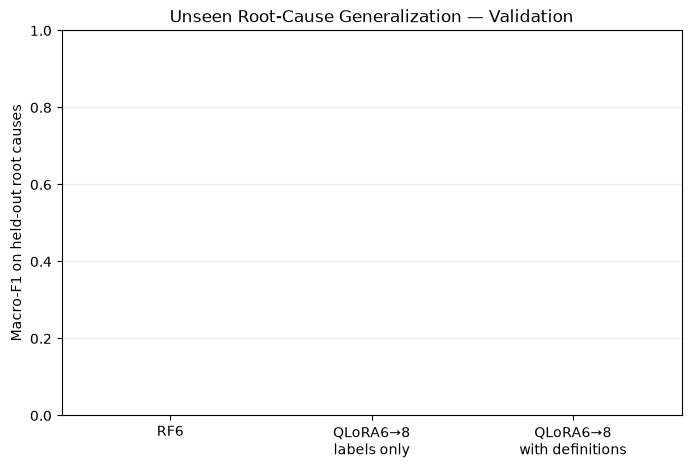

In [29]:
plot_df = pd.DataFrame({
    "method": [
        "RF6",
        "QLoRA6→8\nlabels only",
        "QLoRA6→8\nwith definitions",
    ],
    "macro_f1": [
        rf_val_heldout_metrics["macro_f1"],
        qlora_val_heldout_no_desc_metrics["macro_f1"],
        qlora_val_heldout_metrics["macro_f1"],
    ],
})

plt.figure(figsize=(8, 5))
plt.bar(
    plot_df["method"],
    plot_df["macro_f1"],
)
plt.ylim(0, 1)
plt.ylabel("Macro-F1 on held-out root causes")
plt.title("Unseen Root-Cause Generalization — Validation")
plt.grid(axis="y", alpha=0.25)
plt.show()

## 27. Few-shot Random Forest adaptation

The original zero-shot comparison is asymmetric because the Random Forest's class labels are fixed by its training data. This supplementary experiment introduces **1, 5, 10, 20, or 50 labeled training incidents per held-out class** and measures how quickly the Random Forest adapts.

All adaptation examples come from the **original Train split**, not Validation or Test. The saved results show accuracy rising from **68.75%** with one example per new class to **96.88%** with fifty examples per new class on the held-out-class validation subset.


,labeled_examples_per_new_class,accuracy,macro_f1,balanced_accuracy,n_samples
0,1,0.687500,0.772727,0.687500,96
1,5,0.895833,0.937919,0.895833,96
2,10,0.916667,0.954545,0.916667,96
3,20,0.927083,0.960674,0.927083,96
4,50,0.968750,0.983871,0.968750,96


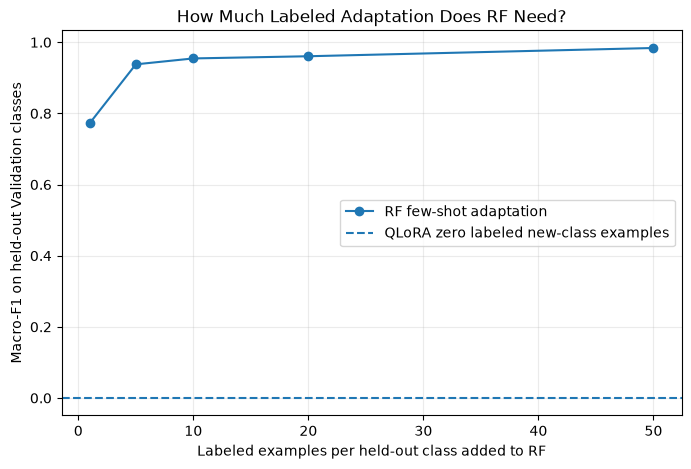

In [30]:
RUN_RF_FEWSHOT = True

if RUN_RF_FEWSHOT:
    K_VALUES = [1, 5, 10, 20, 50]
    fewshot_rows = []

    for k in K_VALUES:
        adaptation_parts = []

        for label in HELD_OUT_LABELS:
            pool = (
                train_heldout_df[
                    train_heldout_df["gold_label"] == label
                ]
                .sample(
                    n=min(k, sum(train_heldout_df["gold_label"] == label)),
                    random_state=RANDOM_SEED,
                )
            )
            adaptation_parts.append(pool)

        adaptation_df = pd.concat(
            adaptation_parts,
            ignore_index=True,
        )

        rf_train_k = pd.concat(
            [train_seen_df, adaptation_df],
            ignore_index=True,
        )

        rf_k = RandomForestClassifier(
            n_estimators=500,
            random_state=RANDOM_SEED,
            class_weight="balanced",
            n_jobs=-1,
        )

        rf_k.fit(
            rf_train_k[SELECTED_FEATURES],
            rf_train_k["gold_label"],
        )

        pred_k = rf_k.predict(
            val_heldout_df[SELECTED_FEATURES]
        )

        metrics_k = metric_dict(
            val_heldout_df["gold_label"],
            pred_k,
            HELD_OUT_LABELS,
        )

        fewshot_rows.append({
            "labeled_examples_per_new_class": k,
            **metrics_k,
        })

    rf_fewshot_df = pd.DataFrame(fewshot_rows)
    display(rf_fewshot_df)

    plt.figure(figsize=(8, 5))
    plt.plot(
        rf_fewshot_df["labeled_examples_per_new_class"],
        rf_fewshot_df["macro_f1"],
        marker="o",
        label="RF few-shot adaptation",
    )
    plt.axhline(
        qlora_val_heldout_metrics["macro_f1"],
        linestyle="--",
        label="QLoRA zero labeled new-class examples",
    )
    plt.xlabel("Labeled examples per held-out class added to RF")
    plt.ylabel("Macro-F1 on held-out Validation classes")
    plt.title("How Much Labeled Adaptation Does RF Need?")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

# Part E — Held-out test evaluation and exports

## 28. Final test protocol

The test evaluation uses the selected held-out classes (C3 and C7), the fixed 18-feature representation, and the trained six-class models. Seen- and unseen-class scores are reported separately so that performance on familiar labels cannot obscure failure on new ones.

The saved run has `RUN_FINAL_TEST=True` and includes the resulting held-out Test outputs.


In [31]:
RUN_FINAL_TEST = True

if RUN_FINAL_TEST:
    # RF on seen Test classes
    rf_test_seen_pred = rf6.predict(
        test_seen_df[SELECTED_FEATURES]
    )
    rf_test_seen_metrics = metric_dict(
        test_seen_df["gold_label"],
        rf_test_seen_pred,
        SEEN_LABELS,
    )

    # RF on unseen Test classes
    rf_test_heldout_pred = rf6.predict(
        test_heldout_df[SELECTED_FEATURES]
    )
    rf_test_heldout_metrics = metric_dict(
        test_heldout_df["gold_label"],
        rf_test_heldout_pred,
        HELD_OUT_LABELS,
    )

    # QLoRA on seen Test classes
    qlora_test_seen_results, qlora_test_seen_metrics = evaluate_llm(
        model,
        test_seen_df,
        allowed_labels=LABELS,
        report_labels=SEEN_LABELS,
        include_descriptions=True,
        max_samples=None,
    )

    # QLoRA on unseen Test classes
    qlora_test_heldout_results, qlora_test_heldout_metrics = evaluate_llm(
        model,
        test_heldout_df,
        allowed_labels=LABELS,
        report_labels=HELD_OUT_LABELS,
        include_descriptions=True,
        max_samples=None,
    )

    final_test_comparison = pd.DataFrame(
        [
            rf_test_seen_metrics,
            qlora_test_seen_metrics,
            rf_test_heldout_metrics,
            qlora_test_heldout_metrics,
        ],
        index=[
            "RF6 — Test seen",
            "QLoRA6→8 — Test seen",
            "RF6 — Test unseen",
            "QLoRA6→8 — Test unseen",
        ],
    )

    display(final_test_comparison)

Processed 25/241
Processed 50/241
Processed 75/241
Processed 100/241
Processed 125/241
Processed 150/241
Processed 175/241
Processed 200/241
Processed 225/241

LLM evaluation
----------------------------------------------------------------------
accuracy            : 1.0
macro_f1            : 1.0
balanced_accuracy   : 1.0
n_samples           : 241

Per-class report
              precision    recall  f1-score   support

          C1     1.0000    1.0000    1.0000        37
          C2     1.0000    1.0000    1.0000        45
          C4     1.0000    1.0000    1.0000        41
          C5     1.0000    1.0000    1.0000        46
          C6     1.0000    1.0000    1.0000        32
          C8     1.0000    1.0000    1.0000        40

    accuracy                         1.0000       241
   macro avg     1.0000    1.0000    1.0000       241
weighted avg     1.0000    1.0000    1.0000       241

invalid_outputs      : 0/241
Processed 25/93
Processed 50/93
Processed 75/93

LLM evaluat

,accuracy,macro_f1,balanced_accuracy,n_samples,invalid_outputs
RF6 — Test seen,0.991701,0.990287,0.990287,241,NaN
QLoRA6→8 — Test seen,1.000000,1.000000,1.000000,241,0.0
RF6 — Test unseen,0.000000,0.000000,0.000000,93,NaN
QLoRA6→8 — Test unseen,0.000000,0.000000,0.000000,93,0.0


## 29. Exported validation predictions and metrics


In [32]:
rf_val_heldout_results.to_csv(
    "new_class_rf_validation_heldout_predictions.csv",
    index=False,
)

qlora_val_seen_results.to_csv(
    "new_class_qlora_validation_seen_predictions.csv",
    index=False,
)

qlora_val_heldout_results.to_csv(
    "new_class_qlora_validation_heldout_predictions.csv",
    index=False,
)

qlora_val_heldout_no_desc_results.to_csv(
    "new_class_qlora_validation_heldout_no_descriptions.csv",
    index=False,
)

validation_comparison.to_csv(
    "new_class_generalization_validation_metrics.csv"
)

semantic_ablation.to_csv(
    "new_class_generalization_semantic_ablation.csv"
)

print("Saved Validation outputs.")

Saved Validation outputs.


# 30. Results and interpretation

The completed experiments show a pronounced difference between **recognition of trained classes** and **transfer to newly introduced classes**.

### Six-class QLoRA performance

On seen validation classes, the fine-tuned Qwen model achieves **98.35% accuracy**. However, with the inference prompt expanded to all eight root-cause definitions, it achieves **0% accuracy on the 96 held-out C3/C7 validation incidents**. Its predictions for those incidents are concentrated in previously trained categories (C1 and C6), indicating that it remains effectively closed-set in this experiment.

The final test reproduces this pattern: **100% accuracy on 241 seen-class incidents**, but **0% accuracy on 93 held-out-class incidents**.

### Role of pretrained knowledge and class definitions

Base Qwen, evaluated with all eight definitions and **without RCA-specific fine-tuning**, correctly identifies **19.79%** of the 96 held-out validation incidents. The six-class QLoRA model performs worse on this specific new-class task. Removing class descriptions from the fine-tuned model's inference prompt leaves unseen-class accuracy at **0%**, so the recorded results do **not** provide evidence of successful semantic-definition transfer after fine-tuning.

### Random Forest comparison and adaptation

The conventional six-class Random Forest achieves **0%** on unseen labels because it cannot emit classes absent from its fitted label set. This is an architectural closed-set limitation, not proof of inferior overall generalization. In the supplementary few-shot experiment, including labeled C3/C7 examples from the original training split enables strong adaptation: accuracy reaches **68.75%** with one example per class and **96.88%** with fifty examples per class on the held-out validation subset.

### Limitations

- The results describe this structured 5G RCA dataset and the specific six-to-eight-class protocol, not arbitrary real-world fault discovery.
- The feature `mob__serving_pci_change_rate_per_second` displays unusually class-specific behavior for some categories and may warrant a separate robustness analysis.
- C7 is defined through a speed threshold (>40 km/h), while the selected diagnostics include affected-user speed. This makes the selected held-out labels different in difficulty and interpretability.
- High seen-class accuracy does not imply that the model can expand its effective label space by reading definitions at inference time.

**Overall finding:** Under the recorded six-class QLoRA training protocol, high supervised diagnostic accuracy does not translate into successful definition-guided recognition of previously unseen root-cause classes.
